In [ ]:
import sys, torch
from packaging.version import Version

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torch CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if sys.version_info < (3, 12):
    raise RuntimeError("SAM 3.1 official setup requires Python 3.12 or newer. Select a current Colab runtime.")
if Version(torch.__version__.split('+')[0]) < Version("2.7.0"):
    raise RuntimeError("PyTorch 2.7+ is required. See the install cell below, install the current official CUDA wheel, then restart the runtime.")
if not torch.cuda.is_available():
    raise RuntimeError("GPU is not enabled. Select Runtime → Change runtime type → T4 GPU.")
if torch.version.cuda and Version(torch.version.cuda) < Version("12.6"):
    raise RuntimeError("The installed PyTorch CUDA runtime is older than 12.6. Install the official CUDA 12.8 PyTorch wheel below, then restart the runtime.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torch CUDA runtime: 13.0
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


In [ ]:
%cd /content
!git clone https://github.com/facebookresearch/sam3.git
%cd /content/sam3
!pip -q install -e .
!pip -q install matplotlib pandas tqdm pillow

/content
Cloning into 'sam3'...
remote: Enumerating objects: 1525, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 1525 (delta 42), reused 29 (delta 29), pack-reused 1457 (from 3)
Receiving objects: 100% (1525/1525), 60.72 MiB | 18.30 MiB/s, done.
Resolving deltas: 100% (597/597), done.
/content/sam3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently tak

In [ ]:
from pathlib import Path
%cd /content
if not Path('/content/sam3').exists():
    !git clone https://github.com/facebookresearch/sam3.git
%cd /content/sam3
!pip -q install -e .
!pip -q install matplotlib pandas tqdm pillow


/content
/content/sam3
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray-einstats 0.11.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.11.1 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.11.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tifffile 2026.10.15 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26.4 whi

In [ ]:
import zipfile
from pathlib import Path
from google.colab import drive

# Mount Google Drive to access the dataset
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/egg_cv_assignment')
ZIP_PATH = PROJECT_DIR / 'egg.v1i.folder.zip'

EXTRACT_DIR = Path('/content/egg_dataset_extracted')
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists():
    raise FileNotFoundError(f'Could not find the dataset ZIP at {ZIP_PATH}. Make sure Google Drive is mounted correctly and the file exists.')

with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
image_paths = sorted(
    p for p in EXTRACT_DIR.rglob('*')
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

print('Images found:', len(image_paths))
for p in image_paths[:10]:
    print(p.relative_to(EXTRACT_DIR))

if not image_paths:
    raise RuntimeError('No images found. Check the ZIP file and extraction path.')

Mounted at /content/drive
Images found: 110
test/egg/not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
test/egg/not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b850927bb3.jpg
test/egg/not_damaged_14_jpg.rf.dc96559078b03433d2b65e5055904af1.jpg
test/egg/not_damaged_152_jpg.rf.a57edb18d395ce87e23f7abccbd1ad69.jpg
test/egg/not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74f1bc143a8.jpg
test/egg/not_damaged_161_jpg.rf.fd216aa5e11e147fc1527478cceae94e.jpg
test/egg/not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd573361f1f.jpg
test/egg/not_damaged_30_jpg.rf.48e9261777355fe67139ac1c5eae596b.jpg
test/egg/not_damaged_43_jpg.rf.66c31342150e751c30214786e72c8683.jpg
test/egg/not_damaged_4_jpg.rf.36c78b63ea4710d9642651ac3292fd58.jpg


In [ ]:
from huggingface_hub import login

# Request access to https://huggingface.co/facebook/sam3.1 before running this cell.
# Use a Hugging Face READ token. The token is not stored in this notebook source.
login()

In [ ]:
import torch
from sam3.model_builder import build_sam3_image_model, download_ckpt_from_hf
from sam3.model.sam3_image_processor import Sam3Processor

# Explicitly download the SAM 3.1 checkpoint (not the older SAM 3 checkpoint).
checkpoint_path = download_ckpt_from_hf(version='sam3.1')
print('Checkpoint downloaded to:', checkpoint_path)

DEVICE = 'cuda'
model = build_sam3_image_model(
    checkpoint_path=checkpoint_path,
    load_from_HF=False,
    device=DEVICE,
    eval_mode=True,
    enable_segmentation=True,
)

CONFIDENCE_THRESHOLD = 0.50
PROMPT = 'egg'
processor = Sam3Processor(
    model,
    device=DEVICE,
    confidence_threshold=CONFIDENCE_THRESHOLD,
)

AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print('SAM 3.1 image model loaded successfully.')
print('Autocast dtype:', AMP_DTYPE)

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

sam3.1_multiplex.pt: reconstructing file:   0%|          |  0.00B / 3.50GB            

sam3.1_multiplex.pt: downloading bytes:           |  0.00B            

Checkpoint downloaded to: /root/.cache/huggingface/hub/models--facebook--sam3.1/snapshots/daa63191845a41281374e725f4c9e51c7a824460/sam3.1_multiplex.pt
loaded /root/.cache/huggingface/hub/models--facebook--sam3.1/snapshots/daa63191845a41281374e725f4c9e51c7a824460/sam3.1_multiplex.pt and found missing and/or unexpected keys:
missing_keys=['backbone.vision_backbone.convs.3.conv_1x1.weight', 'backbone.vision_backbone.convs.3.conv_1x1.bias', 'backbone.vision_backbone.convs.3.conv_3x3.weight', 'backbone.vision_backbone.convs.3.conv_3x3.bias']
SAM 3.1 image model loaded successfully.
Autocast dtype: torch.bfloat16


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import json, time

OUTPUT_DIR = PROJECT_DIR / 'sam3_1_outputs'
MASK_DIR = OUTPUT_DIR / 'instance_masks'
COMBINED_DIR = OUTPUT_DIR / 'combined_masks'
OVERLAY_DIR = OUTPUT_DIR / 'overlays'
META_DIR = OUTPUT_DIR / 'metadata'
for folder in [MASK_DIR, COMBINED_DIR, OVERLAY_DIR, META_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PALETTE = [
    (255, 60, 60), (40, 180, 255), (60, 220, 100),
    (255, 180, 30), (190, 90, 255), (30, 220, 210),
]

def segment_image(image: Image.Image):
    'Return per-instance binary masks, xyxy boxes and confidence scores.'
    image = image.convert('RGB')
    state = processor.set_image(image)
    result = processor.set_text_prompt(state=state, prompt=PROMPT)

    masks_t = result['masks'].detach().cpu()
    # Official processor returns masks as [N, 1, H, W]. Convert to [N, H, W].
    if masks_t.ndim == 4 and masks_t.shape[1] == 1:
        masks_t = masks_t[:, 0]
    masks = masks_t.float().numpy().astype(bool)

    # Cast to standard float32 before calling .numpy() to prevent BFloat16 type errors
    boxes = result['boxes'].detach().cpu().float().numpy()   # xyxy in original image pixels
    scores = result['scores'].detach().cpu().float().numpy()
    return masks, boxes, scores


def make_overlay(image: Image.Image, masks, boxes=None, scores=None, alpha=0.42):
    'Draw a transparent colored overlay and SAM bounding boxes.'
    base = np.asarray(image.convert('RGB')).copy()
    for idx, mask in enumerate(masks):
        color = np.asarray(PALETTE[idx % len(PALETTE)], dtype=np.float32)
        base[mask] = (base[mask] * (1 - alpha) + color * alpha).astype(np.uint8)

    out = Image.fromarray(base)
    draw = ImageDraw.Draw(out)
    if boxes is not None:
        for idx, box in enumerate(boxes):
            x1, y1, x2, y2 = [int(round(v)) for v in box]
            color = PALETTE[idx % len(PALETTE)]
            draw.rectangle((x1, y1, x2, y2), outline=color, width=3)
            label = f"egg {idx + 1}"
            if scores is not None:
                label += f" {float(scores[idx]):.2f}"
            draw.text((x1, max(0, y1 - 16)), label, fill=color)
    return out

print('Output directory:', OUTPUT_DIR)

Output directory: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs


Image: not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
Detected egg instances: 1
Scores: [0.9769999980926514]


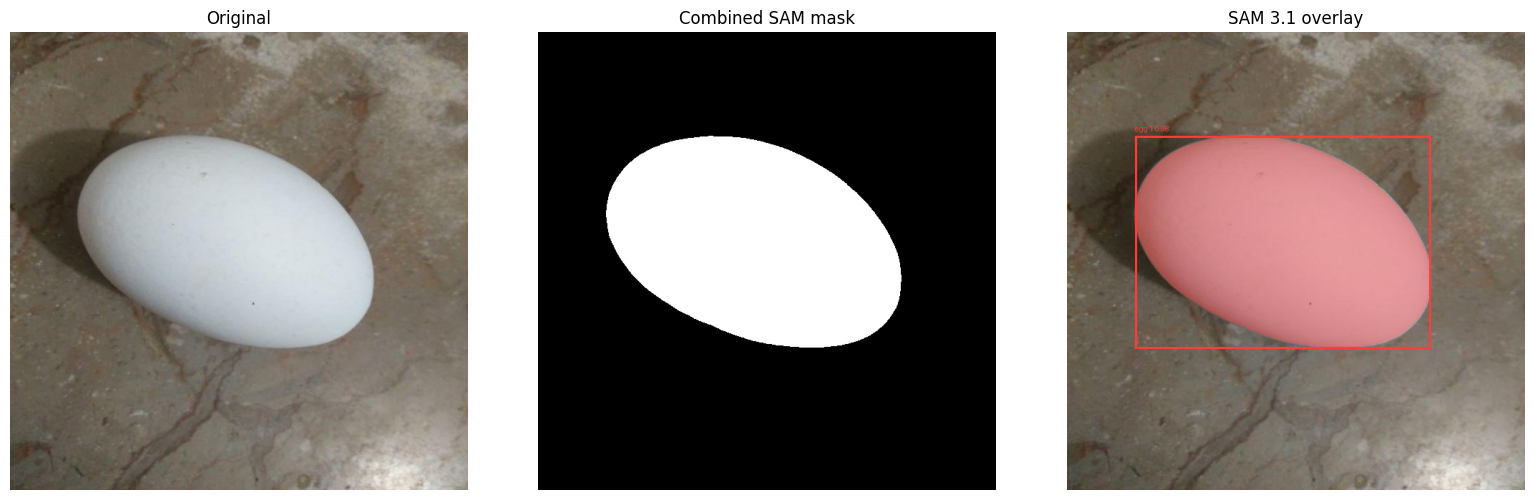

In [ ]:
test_path = image_paths[0]
test_image = Image.open(test_path).convert('RGB')

# Run the inference with autocast to resolve the BFloat16 vs Float mismatch
with torch.amp.autocast('cuda', dtype=AMP_DTYPE):
    test_masks, test_boxes, test_scores = segment_image(test_image)

test_overlay = make_overlay(test_image, test_masks, test_boxes, test_scores)

print('Image:', test_path.name)
print('Detected egg instances:', len(test_masks))
print('Scores:', np.round(test_scores, 3).tolist())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(test_image); axes[0].set_title('Original')
axes[1].imshow(np.any(test_masks, axis=0) if len(test_masks) else np.zeros((test_image.height, test_image.width)), cmap='gray'); axes[1].set_title('Combined SAM mask')
axes[2].imshow(test_overlay); axes[2].set_title('SAM 3.1 overlay')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
records = []
errors = []
start_all = time.time()

for image_path in tqdm(image_paths, desc='SAM 3.1 segmentation'):
    relative = image_path.relative_to(EXTRACT_DIR)
    image = None
    try:
        image = Image.open(image_path).convert('RGB')

        # Run the model with autocast to resolve the BFloat16 vs Float mismatch
        with torch.amp.autocast('cuda', dtype=AMP_DTYPE):
            masks, boxes, scores = segment_image(image)

        h, w = np.asarray(image).shape[:2]

        # Keep the original folder structure to prevent filename collisions.
        per_image_mask_dir = MASK_DIR / relative.parent / relative.stem
        per_image_mask_dir.mkdir(parents=True, exist_ok=True)
        combined_path = COMBINED_DIR / relative.parent / f'{relative.stem}.png'
        overlay_path = OVERLAY_DIR / relative.parent / f'{relative.stem}.jpg'
        meta_path = META_DIR / relative.parent / f'{relative.stem}.json'
        combined_path.parent.mkdir(parents=True, exist_ok=True)
        overlay_path.parent.mkdir(parents=True, exist_ok=True)
        meta_path.parent.mkdir(parents=True, exist_ok=True)

        if len(masks) > 0:
            combined = np.any(masks, axis=0).astype(np.uint8) * 255
        else:
            combined = np.zeros((h, w), dtype=np.uint8)
        Image.fromarray(combined, mode='L').save(combined_path)

        for idx, mask in enumerate(masks):
            instance_path = per_image_mask_dir / f'egg_{idx + 1:02d}.png'
            Image.fromarray(mask.astype(np.uint8) * 255, mode='L').save(instance_path)
            x1, y1, x2, y2 = [float(v) for v in boxes[idx]]
            records.append({
                'image': str(relative),
                'instance_id': idx + 1,
                'score': float(scores[idx]),
                'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
                'mask_area_pixels': int(mask.sum()),
                'mask_path': str(instance_path.relative_to(OUTPUT_DIR)),
                'combined_mask_path': str(combined_path.relative_to(OUTPUT_DIR)),
            })

        if len(masks) == 0:
            records.append({
                'image': str(relative), 'instance_id': None, 'score': None,
                'x1': None, 'y1': None, 'x2': None, 'y2': None,
                'mask_area_pixels': 0, 'mask_path': None,
                'combined_mask_path': str(combined_path.relative_to(OUTPUT_DIR)),
            })

        overlay = make_overlay(image, masks, boxes, scores)
        overlay.save(overlay_path, quality=92)

        with open(meta_path, 'w') as f:
            json.dump({
                'source_image': str(relative),
                'model': 'Meta SAM 3.1 open-weight checkpoint',
                'prompt': PROMPT,
                'confidence_threshold': CONFIDENCE_THRESHOLD,
                'image_width': w,
                'image_height': h,
                'num_instances': int(len(masks)),
                'scores': [float(x) for x in scores],
            }, f, indent=2)

    except Exception as exc:
        errors.append({'image': str(image_path), 'error': repr(exc)})
        print(f'ERROR on {image_path.name}: {exc}')

    finally:
        del image

manifest = pd.DataFrame(records)
manifest_path = OUTPUT_DIR / 'sam3_instance_manifest.csv'
manifest.to_csv(manifest_path, index=False)

with open(OUTPUT_DIR / 'errors.json', 'w') as f:
    json.dump(errors, f, indent=2)

elapsed = time.time() - start_all
print(f'Processed {len(image_paths) - len(errors)} / {len(image_paths)} images in {elapsed / 60:.2f} minutes.')
print('Images with processing errors:', len(errors))

if not manifest.empty and 'instance_id' in manifest.columns:
    print('Detected instances:', int(manifest['instance_id'].notna().sum()))
else:
    print('Detected instances: 0')
print('Manifest:', manifest_path)

SAM 3.1 segmentation:   0%|          | 0/110 [00:00<?, ?it/s]

/tmp/ipykernel_649/2371276566.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(combined, mode='L').save(combined_path)
/tmp/ipykernel_649/2371276566.py:35: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(mask.astype(np.uint8) * 255, mode='L').save(instance_path)


Processed 110 / 110 images in 10.92 minutes.
Images with processing errors: 0
Detected instances: 137
Manifest: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/sam3_instance_manifest.csv


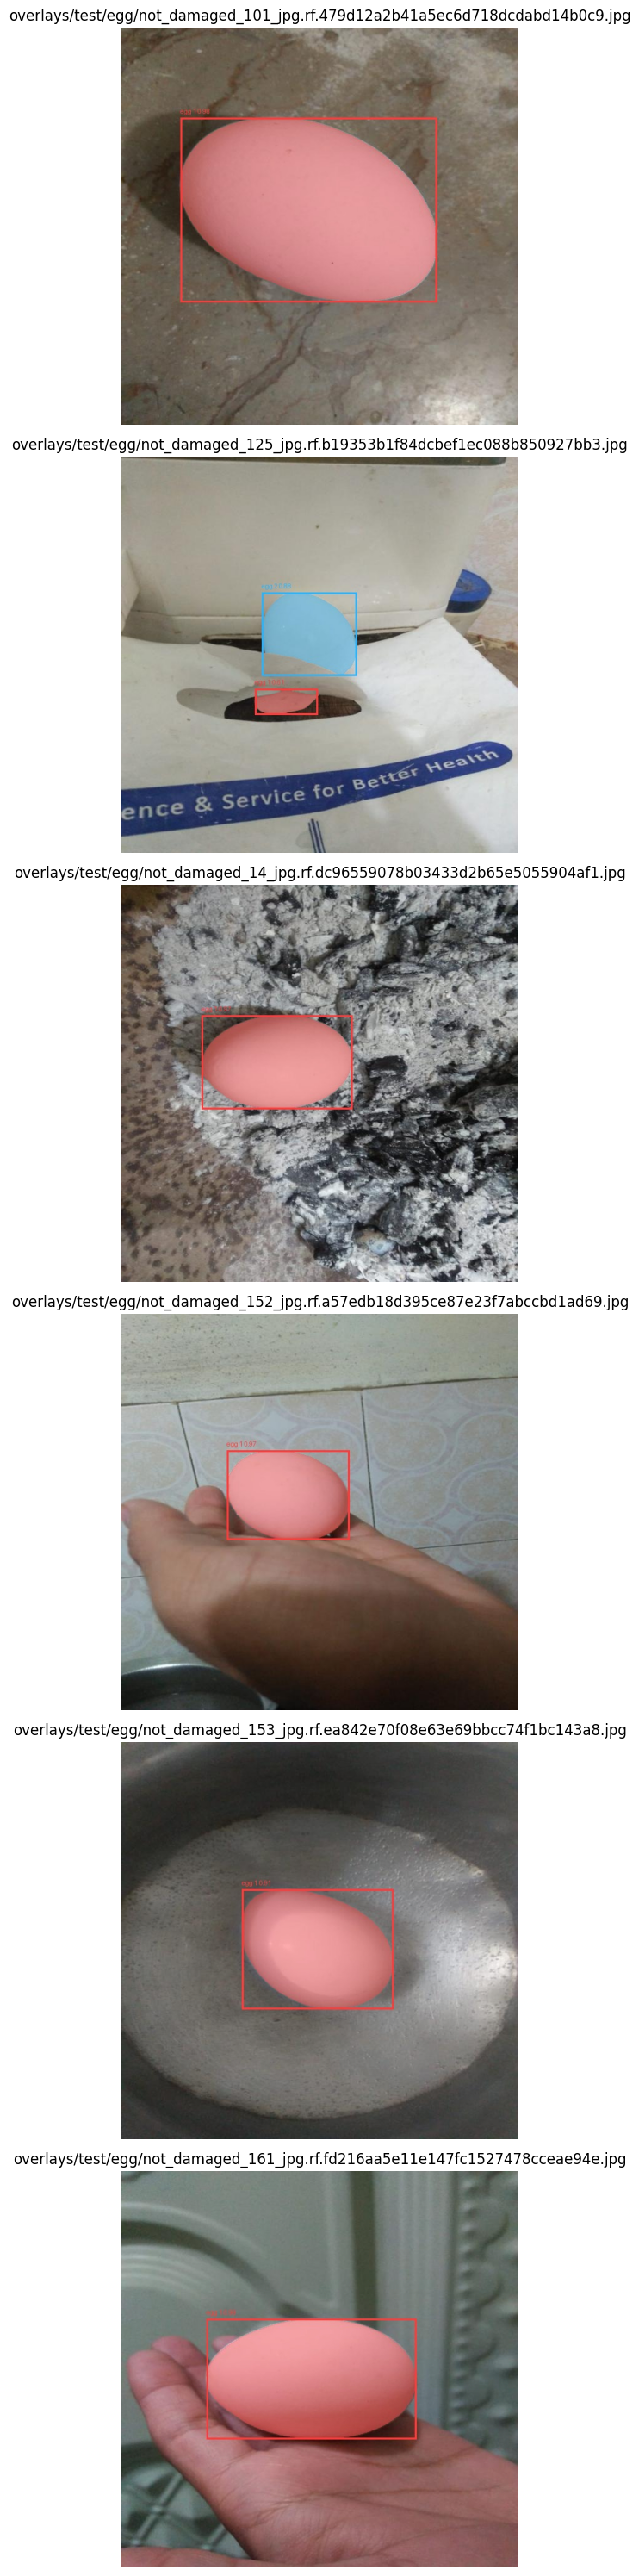

Combined masks: 110
Instance mask files: 137
Overlay images: 110
Saved to Google Drive: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs


In [ ]:
# Show a few overlays from the output folder.
overlay_paths = sorted(OVERLAY_DIR.rglob('*.jpg'))[:6]
if not overlay_paths:
    print('No overlays found.')
else:
    fig, axes = plt.subplots(len(overlay_paths), 1, figsize=(8, 5 * len(overlay_paths)))
    if len(overlay_paths) == 1:
        axes = [axes]
    for ax, path in zip(axes, overlay_paths):
        ax.imshow(Image.open(path))
        ax.set_title(str(path.relative_to(OUTPUT_DIR)))
        ax.axis('off')
    plt.tight_layout(); plt.show()

print('Combined masks:', len(list(COMBINED_DIR.rglob('*.png'))))
print('Instance mask files:', len(list(MASK_DIR.rglob('*.png'))))
print('Overlay images:', len(list(OVERLAY_DIR.rglob('*.jpg'))))
print('Saved to Google Drive:', OUTPUT_DIR)

Task 2 Code Start From Here:

In [ ]:
%pip -q install opencv-python-headless scikit-learn pandas matplotlib pillow tqdm
import cv2, sklearn, numpy, pandas
print('OpenCV:', cv2.__version__)
print('scikit-learn:', sklearn.__version__)

OpenCV: 4.14.0
scikit-learn: 1.6.1


In [ ]:
# Google Drive + dataset + Task 1 SAM mask paths.
from google.colab import drive, files
from pathlib import Path
import shutil, zipfile, os
import pandas as pd

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/egg_cv_assignment')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = PROJECT_DIR / 'egg.v1i.folder.zip'
if not ZIP_PATH.exists():
    print('Upload the same Roboflow version-1 ZIP used in Task 1 (egg.v1i.folder.zip).')
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zip_names:
        raise FileNotFoundError('No dataset ZIP was uploaded.')
    shutil.copy2(zip_names[0], ZIP_PATH)

EXTRACT_DIR = Path('/content/egg_dataset_extracted')
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
image_paths = sorted(p for p in EXTRACT_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
if not image_paths:
    raise RuntimeError('No images found in the dataset ZIP.')

OUTPUT_DIR = PROJECT_DIR / 'sam3_1_outputs'
COMBINED_DIR = OUTPUT_DIR / 'combined_masks'
if not COMBINED_DIR.exists() or not any(COMBINED_DIR.rglob('*.png')):
    raise FileNotFoundError('Task 1 combined masks were not found. Run 01_task_1_sam31_image_segmentation.ipynb first.')
print(f'Dataset images: {len(image_paths)}')
print('SAM combined-mask folder:', COMBINED_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset images: 110
SAM combined-mask folder: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/combined_masks


In [ ]:
import cv2
import hashlib
import json
import math
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm

TASK23_DIR = OUTPUT_DIR / 'task2_task3_results'
SPLIT_DIR = TASK23_DIR / 'splits'
CLASSICAL_MASK_DIR = TASK23_DIR / 'classical_masks'
FAILURE_DIR = TASK23_DIR / 'failure_visualizations'
for _d in [TASK23_DIR, SPLIT_DIR, CLASSICAL_MASK_DIR, FAILURE_DIR]:
    _d.mkdir(parents=True, exist_ok=True)

# Keep only images with a corresponding image file and SAM combined mask.
image_rows = []
missing_reference_masks = []
known_roboflow_split_names = {'train', 'valid', 'validation', 'test'}

for image_path in sorted(Path(p) for p in image_paths):
    rel = image_path.relative_to(EXTRACT_DIR)
    sam_mask_path = COMBINED_DIR / rel.parent / f'{rel.stem}.png'
    if not sam_mask_path.exists():
        missing_reference_masks.append(str(rel))
        continue

    # For the Roboflow classification layout (train/egg/file.jpg), preserve
    # the class folder as a stratification label, not the original split name.
    parts = rel.parts
    if len(parts) >= 3 and parts[0].lower() in known_roboflow_split_names:
        class_label = parts[1]
    elif len(parts) >= 2:
        class_label = parts[-2]
    else:
        class_label = 'unknown'

    image_rows.append({
        'image_path': str(image_path),
        'relative_path': str(rel),
        'sam_mask_path': str(sam_mask_path),
        'class_label': class_label,
    })

if missing_reference_masks:
    print(f'WARNING: {len(missing_reference_masks)} images have no SAM reference mask and will be excluded.')
    print('First missing examples:', missing_reference_masks[:10])

split_df = pd.DataFrame(image_rows)
if len(split_df) < 5:
    raise RuntimeError(f'Only {len(split_df)} images have matching SAM masks. Check COMBINED_DIR.')

# Perceptual hash (64-bit) using a small DCT. This is used only for grouping
# potential near-duplicates before splitting; it is not part of segmentation.
def compute_phash_and_sha256(path, hash_size=8, highfreq_factor=4):
    raw = Path(path).read_bytes()
    sha = hashlib.sha256(raw).hexdigest()
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f'Could not read image: {path}')
    size = hash_size * highfreq_factor
    resized = cv2.resize(gray, (size, size), interpolation=cv2.INTER_AREA)
    dct = cv2.dct(np.float32(resized))
    low = dct[:hash_size, :hash_size].flatten()
    # Exclude the DC coefficient, which mostly represents average brightness.
    values = low[1:]
    median = np.median(values)
    bits = values > median
    phash_int = 0
    for bit in bits:
        phash_int = (phash_int << 1) | int(bit)
    return sha, phash_int

sha_values, phash_values = [], []
for p in tqdm(split_df['image_path'], desc='Hashing images'):
    sha, ph = compute_phash_and_sha256(p)
    sha_values.append(sha)
    phash_values.append(ph)
split_df['sha256'] = sha_values
split_df['phash_hex'] = [f'{v:016x}' for v in phash_values]

# Union-find groups exact duplicates and visually near-identical images.
parent = list(range(len(split_df)))
rank = [0] * len(split_df)
def find_root(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    ra, rb = find_root(a), find_root(b)
    if ra == rb:
        return
    if rank[ra] < rank[rb]:
        ra, rb = rb, ra
    parent[rb] = ra
    if rank[ra] == rank[rb]:
        rank[ra] += 1

# First group exact file duplicates. Then group close perceptual hashes.
sha_to_index = {}
for i, sha in enumerate(sha_values):
    if sha in sha_to_index:
        union(i, sha_to_index[sha])
    else:
        sha_to_index[sha] = i

PHASH_MAX_HAMMING_DISTANCE = 4
near_duplicate_pairs = []
for i in range(len(phash_values)):
    for j in range(i + 1, len(phash_values)):
        distance = (phash_values[i] ^ phash_values[j]).bit_count()
        if distance <= PHASH_MAX_HAMMING_DISTANCE:
            union(i, j)
            near_duplicate_pairs.append({
                'image_a': split_df.iloc[i]['relative_path'],
                'image_b': split_df.iloc[j]['relative_path'],
                'phash_hamming_distance': distance,
            })

roots = [find_root(i) for i in range(len(split_df))]
root_to_group = {root: f'g{idx:04d}' for idx, root in enumerate(sorted(set(roots)))}
split_df['group_id'] = [root_to_group[r] for r in roots]

# Generate multiple grouped candidate splits; choose the one nearest 80:20,
# with class proportions as a secondary objective. No image group is split.
target_eval_count = int(round(0.20 * len(split_df)))
groups = split_df['group_id'].to_numpy()
labels = split_df['class_label'].astype(str).to_numpy()
unique_labels = sorted(set(labels))
class_proportions = {lab: float(np.mean(labels == lab)) for lab in unique_labels}

splitter = GroupShuffleSplit(n_splits=3000, test_size=0.20, random_state=2026)
best_candidate = None
best_score = float('inf')
for train_idx, eval_idx in splitter.split(np.zeros((len(split_df), 1)), groups=groups):
    n_eval = len(eval_idx)
    size_error = abs(n_eval - target_eval_count)
    if n_eval == 0:
        continue
    strat_error = 0.0
    for lab in unique_labels:
        observed = float(np.mean(labels[eval_idx] == lab))
        strat_error += abs(observed - class_proportions[lab])
    score = size_error * 100.0 + strat_error
    if score < best_score:
        best_score = score
        best_candidate = (train_idx, eval_idx)

if best_candidate is None:
    raise RuntimeError('Could not create a grouped development/evaluation split.')
train_idx, eval_idx = best_candidate
split_df['split'] = 'dev'
split_df.loc[eval_idx, 'split'] = 'eval'

# Final leakage assertion.
dev_groups = set(split_df.loc[split_df['split'] == 'dev', 'group_id'])
eval_groups = set(split_df.loc[split_df['split'] == 'eval', 'group_id'])
assert dev_groups.isdisjoint(eval_groups), 'Leakage detected: a duplicate group appears in both splits.'

split_manifest_path = SPLIT_DIR / 'task2_split_manifest.csv'
split_df.to_csv(split_manifest_path, index=False)
pairs_path = SPLIT_DIR / 'near_duplicate_pairs_review.csv'
pd.DataFrame(near_duplicate_pairs).to_csv(pairs_path, index=False)

print(f'Total usable images: {len(split_df)}')
print(f'Dev images: {int((split_df.split == "dev").sum())}')
print(f'Eval images: {int((split_df.split == "eval").sum())}')
print(f'Actual ratio dev:eval = {int((split_df.split == "dev").sum())}:{int((split_df.split == "eval").sum())}')
print(f'Duplicate-aware groups: {split_df.group_id.nunique()}')
print(f'Near-duplicate pairs flagged (pHash distance <= {PHASH_MAX_HAMMING_DISTANCE}): {len(near_duplicate_pairs)}')
print('Class counts by split:')
display(pd.crosstab(split_df['split'], split_df['class_label']))
print('Saved split manifest:', split_manifest_path)
print('Review near-duplicate pairs:', pairs_path)


Hashing images:   0%|          | 0/110 [00:00<?, ?it/s]

Total usable images: 110
Dev images: 88
Eval images: 22
Actual ratio dev:eval = 88:22
Duplicate-aware groups: 109
Near-duplicate pairs flagged (pHash distance <= 4): 1
Class counts by split:


class_label,Unlabeled,egg
split,,
dev,2,86
eval,0,22


Saved split manifest: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/splits/task2_split_manifest.csv
Review near-duplicate pairs: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/splits/near_duplicate_pairs_review.csv


In [ ]:
# Classical methods: all operations are deterministic and CPU-based.
def _fill_holes_with_external_contours(binary_mask):
    mask_u8 = (binary_mask.astype(np.uint8) * 255)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask_u8)
    if contours:
        cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)
    return filled > 0


def _filter_components(mask, cfg):
    h, w = mask.shape
    total_area = float(h * w)
    mask_u8 = mask.astype(np.uint8)
    count, labels_cc, stats, _ = cv2.connectedComponentsWithStats(mask_u8, connectivity=8)
    output = np.zeros((h, w), dtype=np.uint8)

    for label_id in range(1, count):
        x, y, bw, bh, area = [int(v) for v in stats[label_id]]
        area_fraction = area / total_area
        if area_fraction < cfg['min_area_fraction'] or area_fraction > cfg['max_area_fraction']:
            continue
        aspect_ratio = max(bw / max(bh, 1), bh / max(bw, 1))
        if aspect_ratio > cfg['max_aspect_ratio']:
            continue

        component = (labels_cc == label_id).astype(np.uint8) * 255
        contours, _ = cv2.findContours(component, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        contour_area = float(cv2.contourArea(contour))
        hull_area = float(cv2.contourArea(cv2.convexHull(contour)))
        perimeter = float(cv2.arcLength(contour, True))
        solidity = contour_area / max(hull_area, 1.0)
        circularity = (4.0 * math.pi * contour_area) / max(perimeter * perimeter, 1.0)

        if solidity < cfg['min_solidity'] or circularity < cfg['min_circularity']:
            continue
        output[labels_cc == label_id] = 255

    return output > 0


def classical_egg_mask(bgr_image, cfg):
    if bgr_image is None or bgr_image.ndim != 3:
        raise ValueError('Expected a valid BGR image.')

    blurred = cv2.GaussianBlur(bgr_image, (5, 5), 0)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0]
    a = lab[:, :, 1].astype(np.float32) - 128.0
    b = lab[:, :, 2].astype(np.float32) - 128.0
    chroma = cv2.magnitude(a, b)

    method = cfg['method']
    if method == 'gray_otsu':
        gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)
        _, raw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif method == 'hsv':
        hsv = cv2.cvtColor(blurred, cv2.COLOR_BGR2HSV)
        raw = ((hsv[:, :, 1] <= cfg['s_max']) & (hsv[:, :, 2] >= cfg['v_min'])).astype(np.uint8) * 255
    elif method == 'lab_fixed':
        raw = ((L >= cfg['l_min']) & (chroma <= cfg['chroma_max'])).astype(np.uint8) * 255
    elif method == 'lab_otsu_chroma':
        otsu_value, _ = cv2.threshold(L, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        threshold_value = max(float(otsu_value), float(cfg['l_floor']))
        raw = ((L >= threshold_value) & (chroma <= cfg['chroma_max'])).astype(np.uint8) * 255
    elif method == 'lab_adaptive_chroma':
        block = int(cfg['adaptive_block_size'])
        if block % 2 == 0:
            block += 1
        adaptive = cv2.adaptiveThreshold(
            L, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
            block, float(cfg['adaptive_C'])
        )
        raw = ((adaptive > 0) & (chroma <= cfg['chroma_max'])).astype(np.uint8) * 255
    else:
        raise ValueError(f'Unknown method: {method}')

    mask = raw > 0
    open_k = int(cfg['open_kernel'])
    close_k = int(cfg['close_kernel'])
    if open_k > 1:
        if open_k % 2 == 0:
            open_k += 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k))
        mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_OPEN, kernel) > 0
    if close_k > 1:
        if close_k % 2 == 0:
            close_k += 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_k, close_k))
        mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_CLOSE, kernel) > 0

    if cfg['fill_holes']:
        mask = _fill_holes_with_external_contours(mask)
    mask = _filter_components(mask, cfg)
    return mask.astype(bool)


def load_image_and_sam_mask(row):
    bgr = cv2.imread(row['image_path'], cv2.IMREAD_COLOR)
    gt = cv2.imread(row['sam_mask_path'], cv2.IMREAD_GRAYSCALE)
    if bgr is None:
        raise FileNotFoundError(f"Could not read image: {row['image_path']}")
    if gt is None:
        raise FileNotFoundError(f"Could not read SAM mask: {row['sam_mask_path']}")
    if gt.shape[:2] != bgr.shape[:2]:
        gt = cv2.resize(gt, (bgr.shape[1], bgr.shape[0]), interpolation=cv2.INTER_NEAREST)
    return bgr, gt > 127


def binary_metrics(gt, pred):
    gt = np.asarray(gt, dtype=bool)
    pred = np.asarray(pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    tn = int(np.logical_and(~gt, ~pred).sum())
    union = tp + fp + fn
    iou = tp / union if union else 1.0
    dice_denom = 2 * tp + fp + fn
    dice = (2 * tp) / dice_denom if dice_denom else 1.0
    precision = tp / (tp + fp) if (tp + fp) else (1.0 if fn == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) else (1.0 if fp == 0 else 0.0)
    accuracy = (tp + tn) / max(tp + fp + fn + tn, 1)

    # Boundary F1 with a 2-pixel tolerance, supplementary to area-overlap scores.
    kernel = np.ones((5, 5), np.uint8)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    gt_eroded = cv2.erode(gt_u8, np.ones((3, 3), np.uint8))
    pred_eroded = cv2.erode(pred_u8, np.ones((3, 3), np.uint8))
    gt_boundary = (gt_u8 > 0) & (gt_eroded == 0)
    pred_boundary = (pred_u8 > 0) & (pred_eroded == 0)
    if not gt_boundary.any() and not pred_boundary.any():
        boundary_f1 = 1.0
    elif not gt_boundary.any() or not pred_boundary.any():
        boundary_f1 = 0.0
    else:
        gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), kernel) > 0
        pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), kernel) > 0
        b_precision = float((pred_boundary & gt_dilated).sum()) / max(int(pred_boundary.sum()), 1)
        b_recall = float((gt_boundary & pred_dilated).sum()) / max(int(gt_boundary.sum()), 1)
        boundary_f1 = 2 * b_precision * b_recall / max(b_precision + b_recall, 1e-12)

    return {
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'iou': float(iou), 'dice': float(dice),
        'precision': float(precision), 'recall': float(recall),
        'pixel_accuracy': float(accuracy), 'boundary_f1_2px': float(boundary_f1),
        'reference_area_fraction': float(gt.mean()),
        'prediction_area_fraction': float(pred.mean()),
    }


EXPERIMENTS = [
    {
        'name': 'E0_gray_otsu',
        'change': 'Global grayscale Otsu threshold; no chroma constraint.',
        'why': 'Simple brightness baseline to test whether the egg is separable by intensity alone.',
        'cfg': dict(method='gray_otsu', open_kernel=3, close_kernel=5, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.60, max_aspect_ratio=3.0, min_circularity=0.10),
    },
    {
        'name': 'E1_hsv_strict',
        'change': 'HSV threshold with low saturation and high value.',
        'why': 'White egg shells are expected to be bright and relatively unsaturated.',
        'cfg': dict(method='hsv', s_max=65, v_min=165, open_kernel=3, close_kernel=5, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.60, max_aspect_ratio=3.0, min_circularity=0.10),
    },
    {
        'name': 'E2_hsv_loose',
        'change': 'Relaxed HSV saturation/value thresholds.',
        'why': 'Test whether strict HSV misses shaded or warmer egg-shell pixels.',
        'cfg': dict(method='hsv', s_max=95, v_min=140, open_kernel=3, close_kernel=7, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.58, max_aspect_ratio=3.2, min_circularity=0.08),
    },
    {
        'name': 'E3_lab_strict',
        'change': 'CIELAB lightness/chroma with strict brightness and neutral-colour constraints.',
        'why': 'Separate bright, near-neutral shell pixels from coloured skin and darker surroundings.',
        'cfg': dict(method='lab_fixed', l_min=155, chroma_max=28, open_kernel=3, close_kernel=5, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.60, max_aspect_ratio=3.0, min_circularity=0.10),
    },
    {
        'name': 'E4_lab_balanced',
        'change': 'Moderate CIELAB lightness/chroma thresholds with stronger closing.',
        'why': 'Recover more of the shell under shadows while keeping the hand/background out.',
        'cfg': dict(method='lab_fixed', l_min=140, chroma_max=40, open_kernel=3, close_kernel=9, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.58, max_aspect_ratio=3.0, min_circularity=0.08),
    },
    {
        'name': 'E5_lab_loose',
        'change': 'Lower lightness threshold and wider chroma range.',
        'why': 'Test a recall-oriented setting for shaded or slightly coloured eggs.',
        'cfg': dict(method='lab_fixed', l_min=128, chroma_max=52, open_kernel=3, close_kernel=9, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.55, max_aspect_ratio=3.2, min_circularity=0.07),
    },
    {
        'name': 'E6_lab_otsu_chroma',
        'change': 'Otsu-derived lightness threshold plus a chroma cap.',
        'why': 'Adapt the brightness threshold per image instead of using one fixed lightness value.',
        'cfg': dict(method='lab_otsu_chroma', l_floor=130, chroma_max=42, open_kernel=3, close_kernel=7, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.58, max_aspect_ratio=3.0, min_circularity=0.08),
    },
    {
        'name': 'E7_lab_adaptive_chroma',
        'change': 'Local adaptive lightness threshold plus a chroma cap.',
        'why': 'Test local thresholding when illumination varies across the image.',
        'cfg': dict(method='lab_adaptive_chroma', adaptive_block_size=51, adaptive_C=3,
                    chroma_max=42, open_kernel=3, close_kernel=7, fill_holes=True,
                    min_area_fraction=0.0015, max_area_fraction=0.55,
                    min_solidity=0.58, max_aspect_ratio=3.0, min_circularity=0.08),
    },
]


def evaluate_candidate_on_rows(cfg, rows, label):
    per_image = []
    for _, row in tqdm(rows.iterrows(), total=len(rows), desc=label, leave=False):
        bgr, gt = load_image_and_sam_mask(row)
        pred = classical_egg_mask(bgr, cfg)
        scores = binary_metrics(gt, pred)
        scores['relative_path'] = row['relative_path']
        per_image.append(scores)
    metrics_df = pd.DataFrame(per_image)
    return metrics_df


dev_df = split_df[split_df['split'] == 'dev'].reset_index(drop=True)
if len(dev_df) == 0:
    raise RuntimeError('Development split is empty.')

experiment_rows = []
for experiment in EXPERIMENTS:
    dev_metrics = evaluate_candidate_on_rows(experiment['cfg'], dev_df, experiment['name'])
    experiment_rows.append({
        'experiment': experiment['name'],
        'change': experiment['change'],
        'why_tried': experiment['why'],
        'parameters_json': json.dumps(experiment['cfg'], sort_keys=True),
        'dev_macro_iou': float(dev_metrics['iou'].mean()),
        'dev_macro_dice': float(dev_metrics['dice'].mean()),
        'dev_macro_precision': float(dev_metrics['precision'].mean()),
        'dev_macro_recall': float(dev_metrics['recall'].mean()),
        'dev_macro_boundary_f1_2px': float(dev_metrics['boundary_f1_2px'].mean()),
        'dev_micro_iou': float(dev_metrics['tp'].sum() / max((dev_metrics['tp'] + dev_metrics['fp'] + dev_metrics['fn']).sum(), 1)),
        'dev_micro_dice': float((2 * dev_metrics['tp'].sum()) / max((2 * dev_metrics['tp'] + dev_metrics['fp'] + dev_metrics['fn']).sum(), 1)),
    })

experiment_log = pd.DataFrame(experiment_rows).sort_values(
    ['dev_macro_dice', 'dev_macro_iou'], ascending=False
).reset_index(drop=True)
best_name = experiment_log.loc[0, 'experiment']
best_experiment = next(item for item in EXPERIMENTS if item['name'] == best_name)
best_cfg = best_experiment['cfg']
experiment_log['selection_status'] = np.where(experiment_log['experiment'] == best_name, 'KEEP - best dev Dice', 'DISCARD - lower dev Dice')
experiment_log['decision_reason'] = np.where(
    experiment_log['experiment'] == best_name,
    'Selected using development-set macro Dice; evaluation set was not used for selection.',
    'Not selected because its development-set macro Dice was lower than the selected candidate.'
)

experiment_log_path = TASK23_DIR / 'task2_experiment_log.csv'
experiment_log.to_csv(experiment_log_path, index=False)
best_cfg_path = TASK23_DIR / 'selected_classical_config.json'
with open(best_cfg_path, 'w') as f:
    json.dump({'selected_experiment': best_name, 'config': best_cfg}, f, indent=2)

print('Selected candidate:', best_name)
print('Selected configuration:', json.dumps(best_cfg, indent=2))
print('Development experiment results:')
display(experiment_log[['experiment', 'dev_macro_dice', 'dev_macro_iou', 'dev_macro_precision', 'dev_macro_recall', 'selection_status']])
print('Saved experiment log:', experiment_log_path)


E0_gray_otsu:   0%|          | 0/88 [00:00<?, ?it/s]

E1_hsv_strict:   0%|          | 0/88 [00:00<?, ?it/s]

E2_hsv_loose:   0%|          | 0/88 [00:00<?, ?it/s]

E3_lab_strict:   0%|          | 0/88 [00:00<?, ?it/s]

E4_lab_balanced:   0%|          | 0/88 [00:00<?, ?it/s]

E5_lab_loose:   0%|          | 0/88 [00:00<?, ?it/s]

E6_lab_otsu_chroma:   0%|          | 0/88 [00:00<?, ?it/s]

E7_lab_adaptive_chroma:   0%|          | 0/88 [00:00<?, ?it/s]

Selected candidate: E1_hsv_strict
Selected configuration: {
  "method": "hsv",
  "s_max": 65,
  "v_min": 165,
  "open_kernel": 3,
  "close_kernel": 5,
  "fill_holes": true,
  "min_area_fraction": 0.0015,
  "max_area_fraction": 0.55,
  "min_solidity": 0.6,
  "max_aspect_ratio": 3.0,
  "min_circularity": 0.1
}
Development experiment results:


,experiment,dev_macro_dice,dev_macro_iou,dev_macro_precision,dev_macro_recall,selection_status
0,E1_hsv_strict,0.474980,0.381565,0.494814,0.538551,KEEP - best dev Dice
1,E3_lab_strict,0.423488,0.342598,0.407560,0.534600,DISCARD - lower dev Dice
2,E2_hsv_loose,0.386686,0.307184,0.340213,0.515433,DISCARD - lower dev Dice
3,E0_gray_otsu,0.363233,0.292671,0.328284,0.505553,DISCARD - lower dev Dice
4,E6_lab_otsu_chroma,0.359200,0.286908,0.316597,0.484161,DISCARD - lower dev Dice
5,E4_lab_balanced,0.353862,0.278724,0.306267,0.481458,DISCARD - lower dev Dice
6,E5_lab_loose,0.266386,0.206463,0.220306,0.403507,DISCARD - lower dev Dice
7,E7_lab_adaptive_chroma,0.078550,0.058440,0.082897,0.122940,DISCARD - lower dev Dice


Saved experiment log: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/task2_experiment_log.csv


In [ ]:
from pathlib import Path
import cv2
from tqdm.auto import tqdm

dev_mask_dir = CLASSICAL_MASK_DIR / 'dev'
for _, row in tqdm(dev_df.iterrows(), total=len(dev_df), desc='Saving selected dev masks'):
    bgr, _ = load_image_and_sam_mask(row)
    pred = classical_egg_mask(bgr, best_cfg)
    rel = Path(row['relative_path'])
    out = dev_mask_dir / rel.parent / f'{rel.stem}.png'
    out.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(out), pred.astype('uint8') * 255)
print('Development masks saved to:', dev_mask_dir)
print('Task 2 complete. Selected config:', best_cfg_path)
print('Split manifest:', split_manifest_path)
print('Experiment log:', experiment_log_path)

Saving selected dev masks:   0%|          | 0/88 [00:00<?, ?it/s]

Development masks saved to: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/classical_masks/dev
Task 2 complete. Selected config: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/selected_classical_config.json
Split manifest: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/splits/task2_split_manifest.csv
Experiment log: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/task2_experiment_log.csv


Task 3 Code Starts From Here

In [ ]:
%pip -q install opencv-python-headless scikit-learn pandas matplotlib pillow tqdm
import cv2, sklearn, numpy, pandas
print('OpenCV:', cv2.__version__)
print('scikit-learn:', sklearn.__version__)

OpenCV: 4.14.0
scikit-learn: 1.6.1


In [ ]:
import json
# Google Drive + dataset + Task 1 SAM mask paths.
from google.colab import drive, files
from pathlib import Path
import shutil, zipfile, os
import pandas as pd

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/egg_cv_assignment')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = PROJECT_DIR / 'egg.v1i.folder.zip'
if not ZIP_PATH.exists():
    print('Upload the same Roboflow version-1 ZIP used in Task 1 (egg.v1i.folder.zip).')
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zip_names:
        raise FileNotFoundError('No dataset ZIP was uploaded.')
    shutil.copy2(zip_names[0], ZIP_PATH)

EXTRACT_DIR = Path('/content/egg_dataset_extracted')
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
image_paths = sorted(p for p in EXTRACT_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
if not image_paths:
    raise RuntimeError('No images found in the dataset ZIP.')

OUTPUT_DIR = PROJECT_DIR / 'sam3_1_outputs'
COMBINED_DIR = OUTPUT_DIR / 'combined_masks'
if not COMBINED_DIR.exists() or not any(COMBINED_DIR.rglob('*.png')):
    raise FileNotFoundError('Task 1 combined masks were not found. Run 01_task_1_sam31_image_segmentation.ipynb first.')
print(f'Dataset images: {len(image_paths)}')
print('SAM combined-mask folder:', COMBINED_DIR)

TASK23_DIR = OUTPUT_DIR / 'task2_task3_results'
SPLIT_MANIFEST_PATH = TASK23_DIR / 'splits' / 'task2_split_manifest.csv'
BEST_CFG_PATH = TASK23_DIR / 'selected_classical_config.json'
EXPERIMENT_LOG_PATH = TASK23_DIR / 'task2_experiment_log.csv'
CLASSICAL_MASK_DIR = TASK23_DIR / 'classical_masks'
FAILURE_DIR = TASK23_DIR / 'failure_visualizations'
for folder in [TASK23_DIR, CLASSICAL_MASK_DIR, FAILURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
for required in [SPLIT_MANIFEST_PATH, BEST_CFG_PATH, EXPERIMENT_LOG_PATH]:
    if not required.exists():
        raise FileNotFoundError(f'Missing {required}. Run 02_task_2_classical_image_processing.ipynb first.')

split_df = pd.read_csv(SPLIT_MANIFEST_PATH)
# Rebuild absolute paths for this Colab runtime using stable relative paths.
split_df['image_path'] = split_df['relative_path'].apply(lambda r: str(EXTRACT_DIR / Path(r)))
split_df['sam_mask_path'] = split_df['relative_path'].apply(lambda r: str(COMBINED_DIR / Path(r).parent / (Path(r).stem + '.png')))
missing = [p for p in split_df['image_path'].tolist() + split_df['sam_mask_path'].tolist() if not Path(p).exists()]
if missing:
    raise FileNotFoundError('Some dataset images/SAM masks are missing. First missing path: ' + missing[0])

experiment_log = pd.read_csv(EXPERIMENT_LOG_PATH)
with open(BEST_CFG_PATH, 'r') as f:
    frozen_selection = json.load(f)
best_cfg_path = BEST_CFG_PATH
selected_name = frozen_selection['selected_experiment']
frozen_cfg = frozen_selection['config']
dev_df = split_df[split_df['split'] == 'dev'].reset_index(drop=True)
eval_df = split_df[split_df['split'] == 'eval'].reset_index(drop=True)
print('Development images:', len(dev_df))
print('Evaluation images:', len(eval_df))
print('Selected method from Task 2:', selected_name)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset images: 110
SAM combined-mask folder: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/combined_masks
Development images: 88
Evaluation images: 22
Selected method from Task 2: E1_hsv_strict


In [ ]:
import cv2, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display

# Classical methods: all operations are deterministic and CPU-based.
def _fill_holes_with_external_contours(binary_mask):
    mask_u8 = (binary_mask.astype(np.uint8) * 255)
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(mask_u8)
    if contours:
        cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)
    return filled > 0


def _filter_components(mask, cfg):
    h, w = mask.shape
    total_area = float(h * w)
    mask_u8 = mask.astype(np.uint8)
    count, labels_cc, stats, _ = cv2.connectedComponentsWithStats(mask_u8, connectivity=8)
    output = np.zeros((h, w), dtype=np.uint8)

    for label_id in range(1, count):
        x, y, bw, bh, area = [int(v) for v in stats[label_id]]
        area_fraction = area / total_area
        if area_fraction < cfg['min_area_fraction'] or area_fraction > cfg['max_area_fraction']:
            continue
        aspect_ratio = max(bw / max(bh, 1), bh / max(bw, 1))
        if aspect_ratio > cfg['max_aspect_ratio']:
            continue

        component = (labels_cc == label_id).astype(np.uint8) * 255
        contours, _ = cv2.findContours(component, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            continue
        contour = max(contours, key=cv2.contourArea)
        contour_area = float(cv2.contourArea(contour))
        hull_area = float(cv2.contourArea(cv2.convexHull(contour)))
        perimeter = float(cv2.arcLength(contour, True))
        solidity = contour_area / max(hull_area, 1.0)
        circularity = (4.0 * math.pi * contour_area) / max(perimeter * perimeter, 1.0)

        if solidity < cfg['min_solidity'] or circularity < cfg['min_circularity']:
            continue
        output[labels_cc == label_id] = 255

    return output > 0


def classical_egg_mask(bgr_image, cfg):
    if bgr_image is None or bgr_image.ndim != 3:
        raise ValueError('Expected a valid BGR image.')

    blurred = cv2.GaussianBlur(bgr_image, (5, 5), 0)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB)
    L = lab[:, :, 0]
    a = lab[:, :, 1].astype(np.float32) - 128.0
    b = lab[:, :, 2].astype(np.float32) - 128.0
    chroma = cv2.magnitude(a, b)

    method = cfg['method']
    if method == 'gray_otsu':
        gray = cv2.cvtColor(blurred, cv2.COLOR_BGR2GRAY)
        _, raw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif method == 'hsv':
        hsv = cv2.cvtColor(blurred, cv2.COLOR_BGR2HSV)
        raw = ((hsv[:, :, 1] <= cfg['s_max']) & (hsv[:, :, 2] >= cfg['v_min'])).astype(np.uint8) * 255
    elif method == 'lab_fixed':
        raw = ((L >= cfg['l_min']) & (chroma <= cfg['chroma_max'])).astype(np.uint8) * 255
    elif method == 'lab_otsu_chroma':
        otsu_value, _ = cv2.threshold(L, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        threshold_value = max(float(otsu_value), float(cfg['l_floor']))
        raw = ((L >= threshold_value) & (chroma <= cfg['chroma_max'])).astype(np.uint8) * 255
    elif method == 'lab_adaptive_chroma':
        block = int(cfg['adaptive_block_size'])
        if block % 2 == 0:
            block += 1
        adaptive = cv2.adaptiveThreshold(
            L, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
            block, float(cfg['adaptive_C'])
        )
        raw = ((adaptive > 0) & (chroma <= cfg['chroma_max'])).astype(np.uint8) * 255
    else:
        raise ValueError(f'Unknown method: {method}')

    mask = raw > 0
    open_k = int(cfg['open_kernel'])
    close_k = int(cfg['close_kernel'])
    if open_k > 1:
        if open_k % 2 == 0:
            open_k += 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_k, open_k))
        mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_OPEN, kernel) > 0
    if close_k > 1:
        if close_k % 2 == 0:
            close_k += 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_k, close_k))
        mask = cv2.morphologyEx(mask.astype(np.uint8) * 255, cv2.MORPH_CLOSE, kernel) > 0

    if cfg['fill_holes']:
        mask = _fill_holes_with_external_contours(mask)
    mask = _filter_components(mask, cfg)
    return mask.astype(bool)


def load_image_and_sam_mask(row):
    bgr = cv2.imread(row['image_path'], cv2.IMREAD_COLOR)
    gt = cv2.imread(row['sam_mask_path'], cv2.IMREAD_GRAYSCALE)
    if bgr is None:
        raise FileNotFoundError(f"Could not read image: {row['image_path']}")
    if gt is None:
        raise FileNotFoundError(f"Could not read SAM mask: {row['sam_mask_path']}")
    if gt.shape[:2] != bgr.shape[:2]:
        gt = cv2.resize(gt, (bgr.shape[1], bgr.shape[0]), interpolation=cv2.INTER_NEAREST)
    return bgr, gt > 127


def binary_metrics(gt, pred):
    gt = np.asarray(gt, dtype=bool)
    pred = np.asarray(pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    tn = int(np.logical_and(~gt, ~pred).sum())
    union = tp + fp + fn
    iou = tp / union if union else 1.0
    dice_denom = 2 * tp + fp + fn
    dice = (2 * tp) / dice_denom if dice_denom else 1.0
    precision = tp / (tp + fp) if (tp + fp) else (1.0 if fn == 0 else 0.0)
    recall = tp / (tp + fn) if (tp + fn) else (1.0 if fp == 0 else 0.0)
    accuracy = (tp + tn) / max(tp + fp + fn + tn, 1)

    # Boundary F1 with a 2-pixel tolerance, supplementary to area-overlap scores.
    kernel = np.ones((5, 5), np.uint8)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    gt_eroded = cv2.erode(gt_u8, np.ones((3, 3), np.uint8))
    pred_eroded = cv2.erode(pred_u8, np.ones((3, 3), np.uint8))
    gt_boundary = (gt_u8 > 0) & (gt_eroded == 0)
    pred_boundary = (pred_u8 > 0) & (pred_eroded == 0)
    if not gt_boundary.any() and not pred_boundary.any():
        boundary_f1 = 1.0
    elif not gt_boundary.any() or not pred_boundary.any():
        boundary_f1 = 0.0
    else:
        gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), kernel) > 0
        pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), kernel) > 0
        b_precision = float((pred_boundary & gt_dilated).sum()) / max(int(pred_boundary.sum()), 1)
        b_recall = float((gt_boundary & pred_dilated).sum()) / max(int(gt_boundary.sum()), 1)
        boundary_f1 = 2 * b_precision * b_recall / max(b_precision + b_recall, 1e-12)

    return {
        'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'iou': float(iou), 'dice': float(dice),
        'precision': float(precision), 'recall': float(recall),
        'pixel_accuracy': float(accuracy), 'boundary_f1_2px': float(boundary_f1),
        'reference_area_fraction': float(gt.mean()),
        'prediction_area_fraction': float(pred.mean()),
    }




In [ ]:
# Re-load the selected configuration from disk to make the evaluation step explicit.
with open(best_cfg_path, 'r') as f:
    frozen_selection = json.load(f)
selected_name = frozen_selection['selected_experiment']
frozen_cfg = frozen_selection['config']

# Save development metrics of selected method separately for the report.
selected_dev_row = experiment_log.loc[experiment_log['experiment'] == selected_name].iloc[0]

eval_df = split_df[split_df['split'] == 'eval'].reset_index(drop=True)
if len(eval_df) == 0:
    raise RuntimeError('Evaluation split is empty.')

eval_records = []
eval_cache = {}
for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc='Locked evaluation'):
    bgr, gt = load_image_and_sam_mask(row)
    pred = classical_egg_mask(bgr, frozen_cfg)
    metrics = binary_metrics(gt, pred)
    metrics.update({
        'relative_path': row['relative_path'],
        'class_label': row['class_label'],
    })
    eval_records.append(metrics)
    eval_cache[row['relative_path']] = {
        'bgr': bgr,
        'gt': gt,
        'pred': pred,
    }

per_image_eval = pd.DataFrame(eval_records).sort_values('iou').reset_index(drop=True)
per_image_eval_path = TASK23_DIR / 'task3_eval_metrics_per_image.csv'
per_image_eval.to_csv(per_image_eval_path, index=False)

# Save classical masks for all evaluation images. Use the same relative structure.
for rel, item in eval_cache.items():
    rel_path = Path(rel)
    save_path = CLASSICAL_MASK_DIR / 'eval' / rel_path.parent / f'{rel_path.stem}.png'
    save_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(save_path), item['pred'].astype(np.uint8) * 255)

# Aggregate pixel counts before deriving micro metrics.
tp_total = int(per_image_eval['tp'].sum())
fp_total = int(per_image_eval['fp'].sum())
fn_total = int(per_image_eval['fn'].sum())
tn_total = int(per_image_eval['tn'].sum())
union_total = tp_total + fp_total + fn_total
micro_iou = tp_total / union_total if union_total else 1.0
micro_dice = (2 * tp_total) / max(2 * tp_total + fp_total + fn_total, 1)
micro_precision = tp_total / max(tp_total + fp_total, 1)
micro_recall = tp_total / max(tp_total + fn_total, 1)
micro_accuracy = (tp_total + tn_total) / max(tp_total + fp_total + fn_total + tn_total, 1)

nonempty_ref = per_image_eval[per_image_eval['reference_area_fraction'] > 0]
summary = {
    'selected_experiment': selected_name,
    'frozen_parameters': frozen_cfg,
    'num_dev_images': int(len(dev_df)),
    'num_eval_images': int(len(eval_df)),
    'dev_macro_dice': float(selected_dev_row['dev_macro_dice']),
    'dev_macro_iou': float(selected_dev_row['dev_macro_iou']),
    'eval_macro_iou': float(per_image_eval['iou'].mean()),
    'eval_macro_dice': float(per_image_eval['dice'].mean()),
    'eval_macro_precision': float(per_image_eval['precision'].mean()),
    'eval_macro_recall': float(per_image_eval['recall'].mean()),
    'eval_macro_pixel_accuracy': float(per_image_eval['pixel_accuracy'].mean()),
    'eval_macro_boundary_f1_2px': float(per_image_eval['boundary_f1_2px'].mean()),
    'eval_macro_dice_nonempty_reference_images': float(nonempty_ref['dice'].mean()) if len(nonempty_ref) else None,
    'eval_micro_iou': float(micro_iou),
    'eval_micro_dice': float(micro_dice),
    'eval_micro_precision': float(micro_precision),
    'eval_micro_recall': float(micro_recall),
    'eval_micro_pixel_accuracy': float(micro_accuracy),
    'total_tp_pixels': tp_total,
    'total_fp_pixels': fp_total,
    'total_fn_pixels': fn_total,
    'total_tn_pixels': tn_total,
    'reference_definition': 'SAM 3.1 combined binary masks; pseudo-ground truth, not human annotation.',
    'evaluation_note': 'Parameters selected on dev split only; this eval split was not used for tuning.',
}
summary_path = TASK23_DIR / 'task3_eval_summary.json'
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)

print('Selected method:', selected_name)
print('Held-out evaluation summary:')
display(pd.DataFrame([{
    'macro IoU': summary['eval_macro_iou'],
    'macro Dice': summary['eval_macro_dice'],
    'macro Precision': summary['eval_macro_precision'],
    'macro Recall': summary['eval_macro_recall'],
    'micro IoU': summary['eval_micro_iou'],
    'micro Dice': summary['eval_micro_dice'],
    'Boundary F1 (2px)': summary['eval_macro_boundary_f1_2px'],
}]))
print('Saved per-image metrics:', per_image_eval_path)
print('Saved summary:', summary_path)


Locked evaluation:   0%|          | 0/22 [00:00<?, ?it/s]

Selected method: E1_hsv_strict
Held-out evaluation summary:


,macro IoU,macro Dice,macro Precision,macro Recall,micro IoU,micro Dice,Boundary F1 (2px)
0,0.452672,0.553226,0.597666,0.589054,0.375413,0.545891,0.26743


Saved per-image metrics: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/task3_eval_metrics_per_image.csv
Saved summary: /content/drive/MyDrive/egg_cv_assignment/sam3_1_outputs/task2_task3_results/task3_eval_summary.json


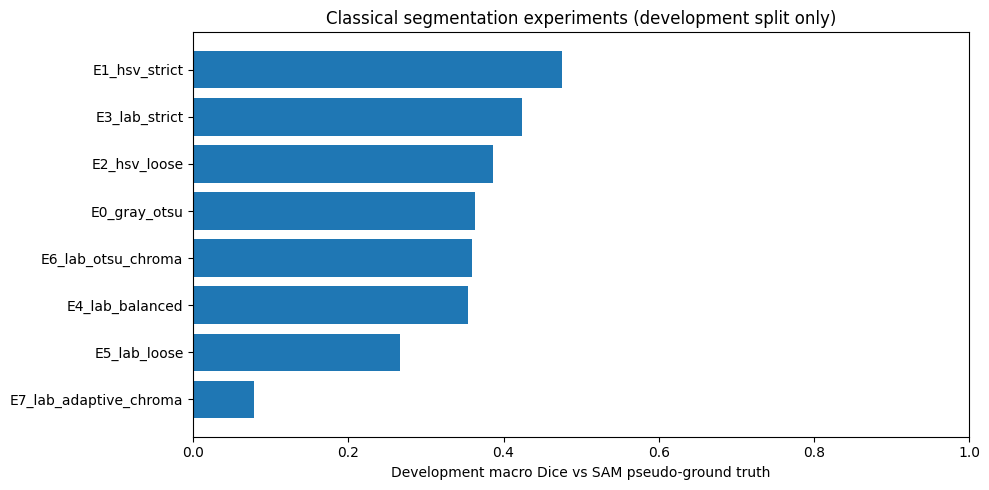

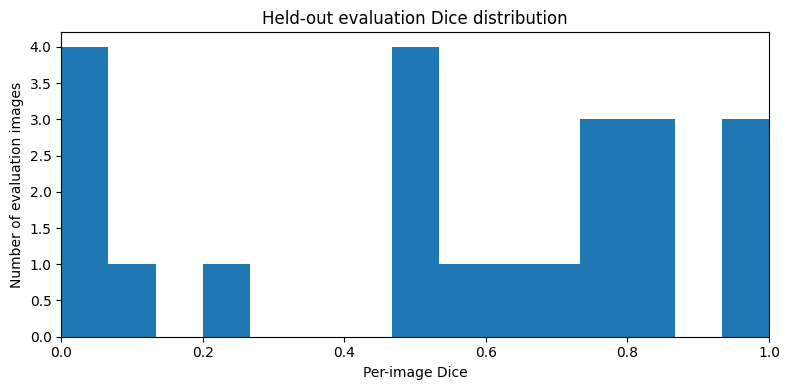

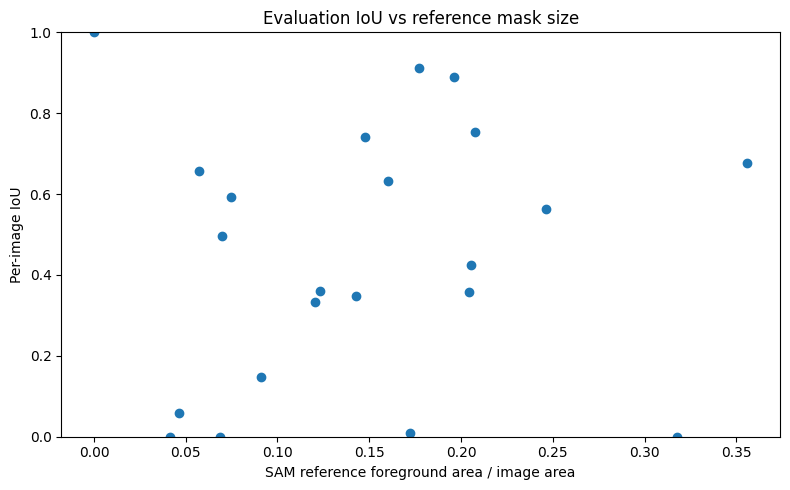

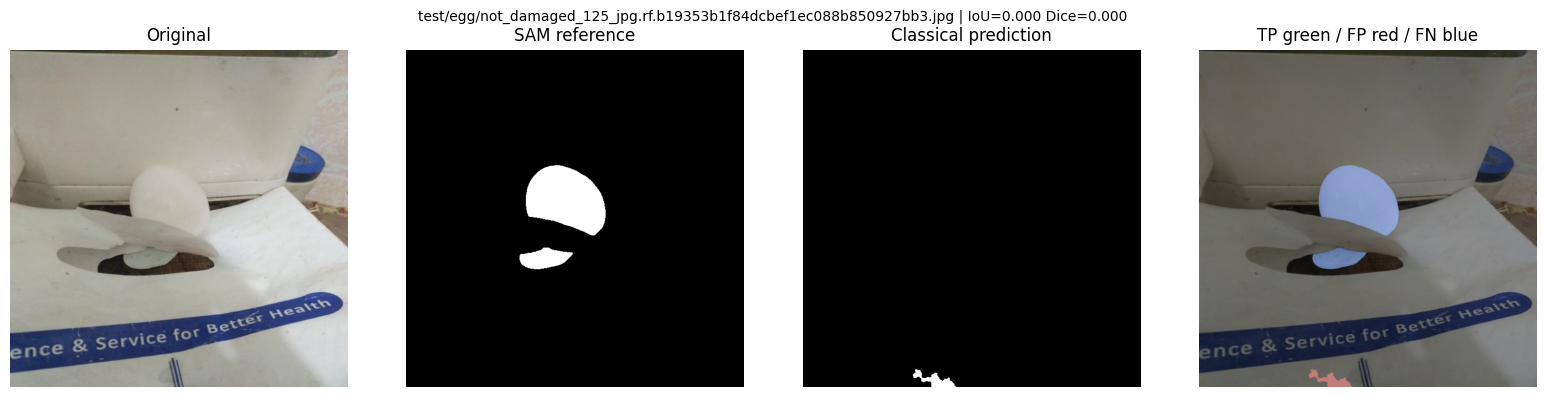

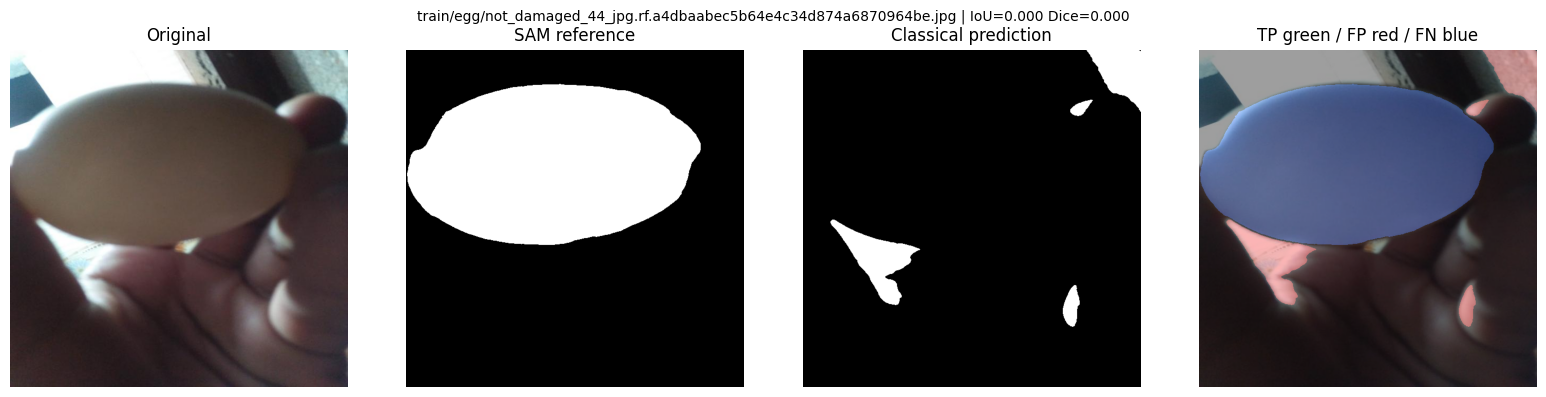

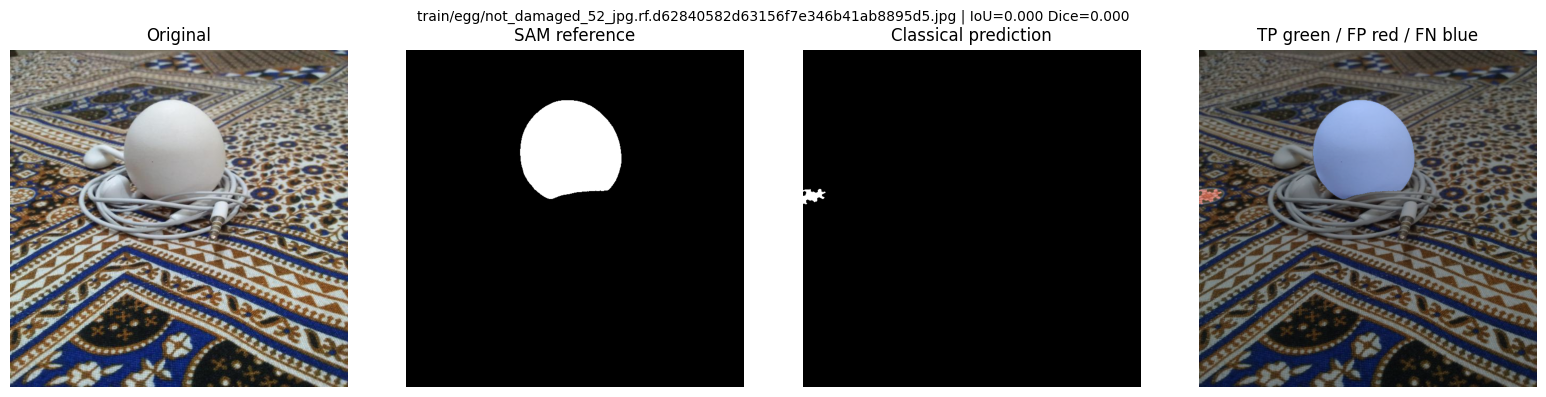

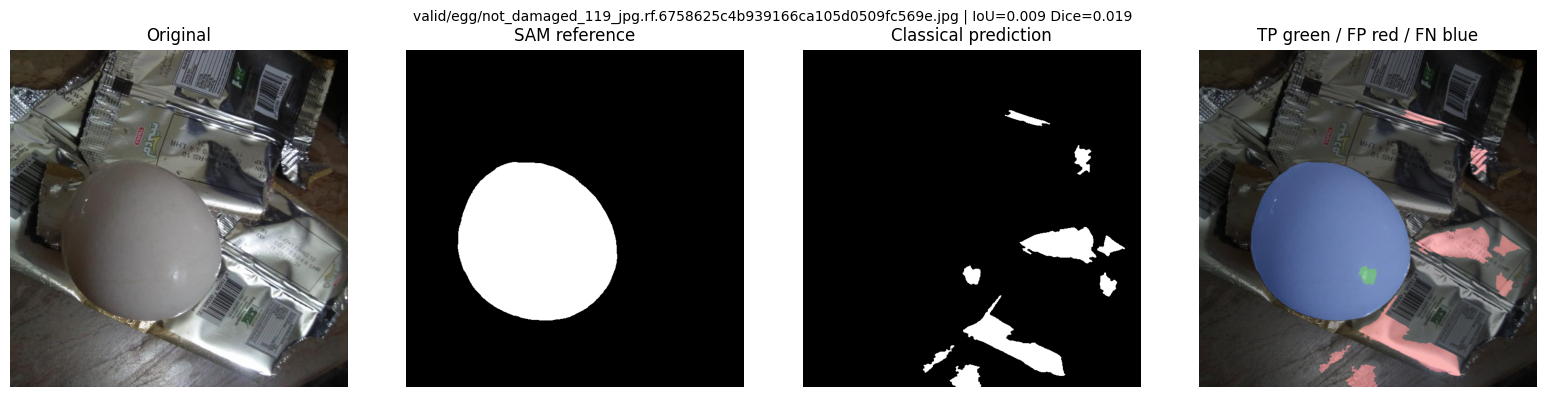

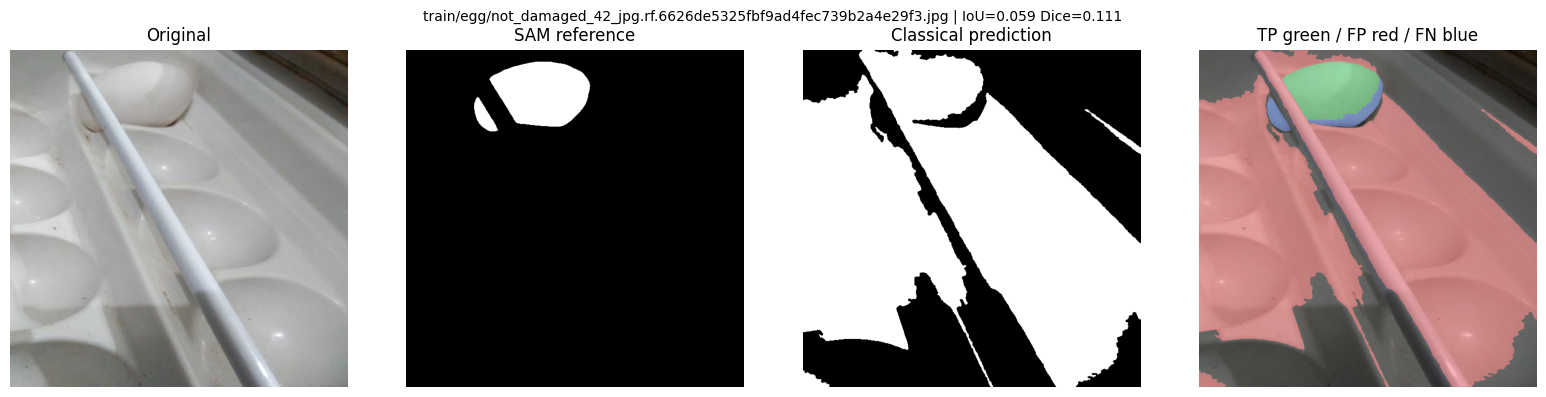

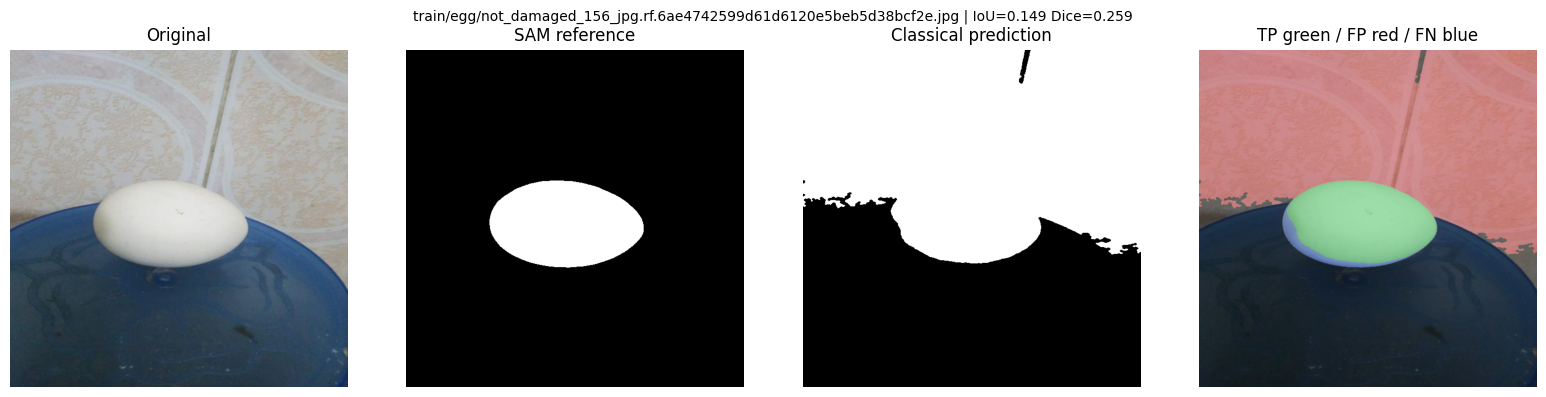

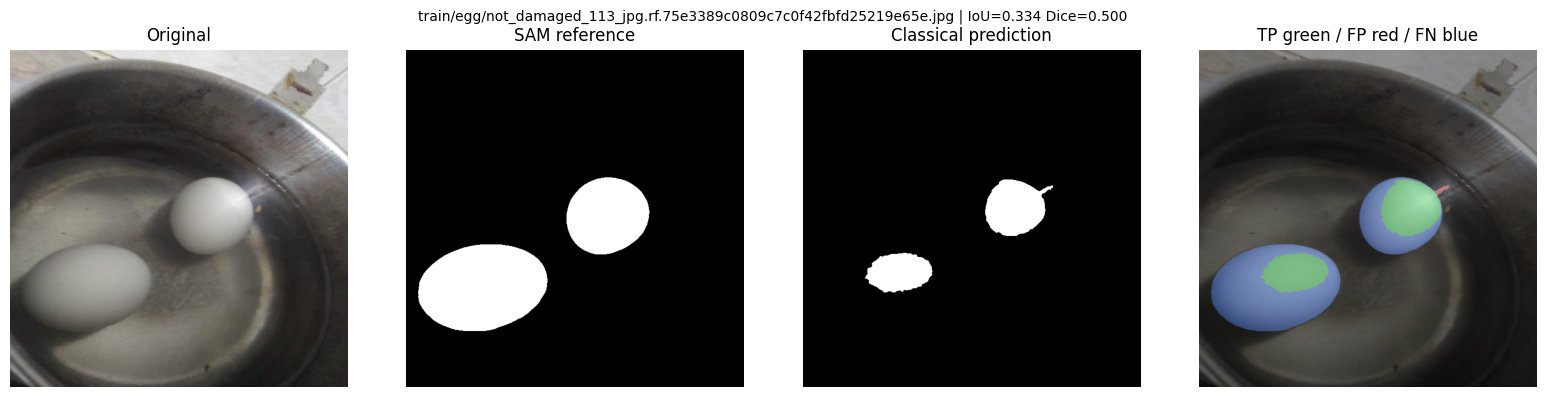

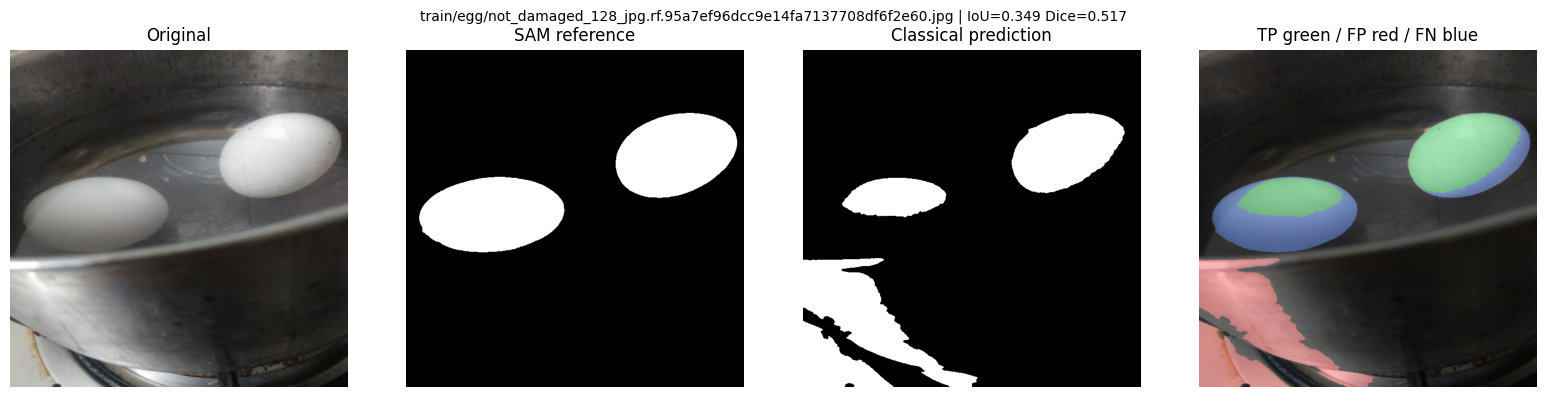

Saving final masks for all images:   0%|          | 0/110 [00:00<?, ?it/s]

In [ ]:
import matplotlib.pyplot as plt

# Plot candidate performance on dev only.
plot_df = experiment_log.sort_values('dev_macro_dice', ascending=True)
plt.figure(figsize=(10, 5))
plt.barh(plot_df['experiment'], plot_df['dev_macro_dice'])
plt.xlabel('Development macro Dice vs SAM pseudo-ground truth')
plt.title('Classical segmentation experiments (development split only)')
plt.xlim(0, 1)
plt.tight_layout()
experiment_plot_path = TASK23_DIR / 'task2_dev_experiment_comparison.png'
plt.savefig(experiment_plot_path, dpi=180, bbox_inches='tight')
plt.show()

# Evaluation score distribution.
plt.figure(figsize=(8, 4))
plt.hist(per_image_eval['dice'], bins=15)
plt.xlabel('Per-image Dice')
plt.ylabel('Number of evaluation images')
plt.title('Held-out evaluation Dice distribution')
plt.xlim(0, 1)
plt.tight_layout()
eval_hist_path = TASK23_DIR / 'task3_eval_dice_histogram.png'
plt.savefig(eval_hist_path, dpi=180, bbox_inches='tight')
plt.show()

# Plot metric versus reference mask area to see whether small/large eggs are harder.
plt.figure(figsize=(8, 5))
plt.scatter(per_image_eval['reference_area_fraction'], per_image_eval['iou'])
plt.xlabel('SAM reference foreground area / image area')
plt.ylabel('Per-image IoU')
plt.title('Evaluation IoU vs reference mask size')
plt.ylim(0, 1)
plt.tight_layout()
area_plot_path = TASK23_DIR / 'task3_iou_vs_reference_area.png'
plt.savefig(area_plot_path, dpi=180, bbox_inches='tight')
plt.show()

# Visualize up to 8 worst evaluation samples.
num_examples = min(8, len(per_image_eval))
worst_rows = per_image_eval.head(num_examples)
for rank, row in worst_rows.iterrows():
    rel = row['relative_path']
    item = eval_cache[rel]
    rgb = cv2.cvtColor(item['bgr'], cv2.COLOR_BGR2RGB)
    gt = item['gt']
    pred = item['pred']

    # Error map: TP green, FP red, FN blue.
    error_rgb = np.zeros_like(rgb)
    tp_mask = pred & gt
    fp_mask = pred & ~gt
    fn_mask = ~pred & gt
    error_rgb[tp_mask] = (40, 210, 80)
    error_rgb[fp_mask] = (245, 60, 60)
    error_rgb[fn_mask] = (50, 110, 245)
    overlay = cv2.addWeighted(rgb, 0.62, error_rgb, 0.38, 0)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(rgb); axes[0].set_title('Original')
    axes[1].imshow(gt, cmap='gray'); axes[1].set_title('SAM reference')
    axes[2].imshow(pred, cmap='gray'); axes[2].set_title('Classical prediction')
    axes[3].imshow(overlay); axes[3].set_title('TP green / FP red / FN blue')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f"{rel} | IoU={row['iou']:.3f} Dice={row['dice']:.3f}", fontsize=10)
    fig.tight_layout()
    safe_name = Path(rel).stem.replace(' ', '_')
    fig_path = FAILURE_DIR / f'failure_{rank+1:02d}_{safe_name}.png'
    fig.savefig(fig_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Apply the frozen best configuration to every dataset image and save final masks.
# This creates Task 2 outputs for both dev and eval images; it does not change parameters.
FINAL_MASK_DIR = TASK23_DIR / 'final_classical_masks'
for _, row in tqdm(split_df.iterrows(), total=len(split_df), desc='Saving final masks for all images'):
    bgr = cv2.imread(row['image_path'], cv2.IMREAD_COLOR)
    if bgr is None:
        print('Skipping unreadable image:', row['relative_path'])
        continue
    pred = classical_egg_mask(bgr, frozen_cfg)
    rel_path = Path(row['relative_path'])
    save_path = FINAL_MASK_DIR / row['split'] / rel_path.parent / f'{rel_path.stem}.png'
    save_path.parent.mkdir(parents=True, exist_ok=True)
    cv2.imwrite(str(save_path), pred.astype(np.uint8) * 255)

# Write a concise machine-readable report bundle.
report_bundle = {
    'split_manifest': str(split_manifest_path),
    'near_duplicate_pairs_review': str(pairs_path),
    'experiment_log': str(experiment_log_path),
    'selected_config': str(best_cfg_path),
    'per_image_eval_metrics': str(per_image_eval_path),
    'eval_summary': str(summary_path),
    'experiment_plot': str(experiment_plot_path),
    'eval_histogram': str(eval_hist_path),
    'iou_vs_reference_area_plot': str(area_plot_path),
    'failure_visualizations_dir': str(FAILURE_DIR),
}
with open(TASK23_DIR / 'task2_task3_artifacts.json', 'w') as f:
    json.dump(report_bundle, f, indent=2)

print('Task 2/3 outputs saved under:', TASK23_DIR)
print(json.dumps(report_bundle, indent=2))
